# Qiskit Fall Fest — Quantum Computing 101 (Hands‑On)

Welcome! This beginner‑friendly notebook introduces quantum computing concepts through **short explanations** and **do‑it‑yourself challenges** using Qiskit.

**Prerequisites:**  *no prior* quantum background  
**You’ll learn to:** qubits & superposition, measurement, entanglement.

> 🧭 **How to use this notebook**
> 1) Run cells top‑to‑bottom.  
> 2) Complete the **🧩 Challenges** where you see “YOUR CODE HERE”.  
> 3) Use the quick tests to check your work.  


## 0. Setup (once per environment)

If you're running on a fresh environment, install the packages below.  
If you're on a managed environment (e.g., classroom PCs), you can skip the install and just run the imports.

In [ ]:
# If needed, uncomment the next line (and re-run) to install/upgrade Qiskit locally.
!pip -q install "qiskit>=1.1" "qiskit-aer>=0.14" "qiskit-ibm-runtime>=0.25" --upgrade
!pip install -q pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 51.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.4/377.4 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 7.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 4.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_histogram,\
                                 plot_bloch_multivector,\
                                 plot_distribution
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
# Import the Parameter module from the Qiskit's Circuit module
from qiskit.circuit import Parameter
# Import the Options, Session, and Sampler v2 modules
# from the Qiskit's IBM Runtime library
from qiskit_ibm_runtime import Options, Session,\
                               SamplerV2 as Sampler
# Import the Generate Preset Pass Manager module
# from the Qiskit's Transpiler module
from qiskit.transpiler import generate_preset_pass_manager


# (Optional) Fake backends with realistic noise (no IBM account required)
try:
    from qiskit_ibm_runtime.fake_provider import FakeManilaV2
    HAS_FAKE = True
except Exception:
    HAS_FAKE = False

from math import pi
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility for simulators that support it
np.random.seed(42)
print("Imports OK. Qiskit notebook is ready!")
print("Fake noisy backend available:", HAS_FAKE)

Imports OK. Qiskit notebook is ready!
Fake noisy backend available: True


### Helper Utilities

We’ll use these helpers to simulate circuits and check your answers.

In [ ]:
def run_counts(qc, shots=1000, seed=42):
    """Compile and run a circuit on AerSimulator and return counts."""
    sim = AerSimulator(seed_simulator=seed)
    tqc = transpile(qc, sim)
    res = sim.run(tqc, shots=shots).result()
    return res.get_counts()

def probs_from_counts(counts):
    total = sum(counts.values())
    return {k: v/total for k, v in counts.items()}

def almost_equal(a, b, tol=0.05):
    return abs(a - b) <= tol

def complete_counts(counts: dict) -> dict:
    for key in counts:
      n_bits = len(key)
      break
    all_keys = [format(i, f'0{n_bits}b') for i in range(2**n_bits)]
    return {k: counts.get(k, 0) for k in all_keys}



### Building the first quantum circuit


Statevector([1.+0.j, 0.+0.j],
            dims=(2,))



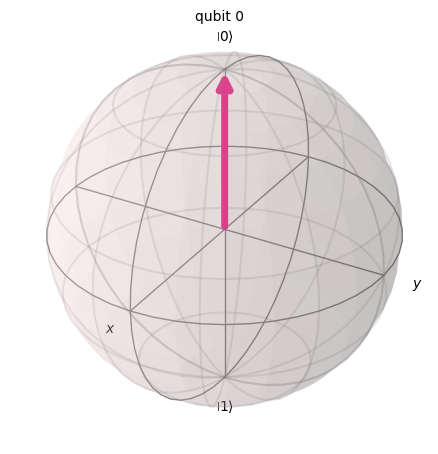

In [ ]:
qc = QuantumCircuit(1)

# See the statevector
out_vector = Statevector(qc)
print(f"\n{out_vector}\n")

# Draw a Bloch sphere
plot_bloch_multivector(out_vector)


By design, all qubits start in the state $|0\rangle$. The two basic states are mathematically represented by the column vectors:

\begin{align}
|0\rangle = \begin{pmatrix}
1 \\
0
\end{pmatrix}, \qquad
|1\rangle = \begin{pmatrix}
0 \\
1
\end{pmatrix}
\end{align}

### 1 Pauli Gates

The **Pauli gates** ($X$, $Y$, $Z$) correspond to $\pi$-radian rotations around axes of the Bloch sphere.





Now lets apply a few gates, first lets see the applciation of a NOT gate, this gate flips the state.

\begin{align}
        X = \begin{pmatrix}
        0 & 1 \\
        1 & 0
        \end{pmatrix}.
\end{align}


If we apply the $X$ to the initial state

\begin{align}
        X |0\rangle = \begin{pmatrix}
        0 & 1 \\
        1 & 0
        \end{pmatrix}
        \begin{pmatrix}
        1\\
        0
        \end{pmatrix}=
        \begin{pmatrix}
        0 \\
        1
        \end{pmatrix}= |1\rangle
\end{align}


If we apply the $X$ to the $|1⟩$ state

\begin{align}
        X |1\rangle = \begin{pmatrix}
        0 & 1 \\
        1 & 0
        \end{pmatrix}
        \begin{pmatrix}
        0\\
        1
        \end{pmatrix}=
        \begin{pmatrix}
        1 \\
        0
        \end{pmatrix}= |0\rangle
\end{align}



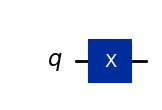

In [ ]:
# Define the quantum circuit with only one quantum qubit
qc = QuantumCircuit(1)
# Apply a X gate to qubit 0
qc.x(0)
# Draw the circuit
qc.draw("mpl")


Statevector([0.+0.j, 1.+0.j],
            dims=(2,))



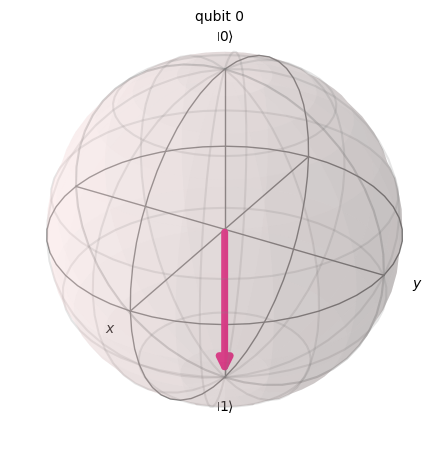

In [ ]:
# visualize the statevector
out_vector = Statevector(qc)
print(f"\n{out_vector}\n")

# Draw a Bloch sphere
plot_bloch_multivector(out_vector)

In quantum computing, the **$Y$** and **$Z$** gates are part of the set of Pauli operators, each representing a rotation around a principal axis of the Bloch sphere. The **$Y$ gate** corresponds to a rotation of the qubit state by $\pi$ radians around the **Y-axis**, and is defined by the matrix:

\begin{align}
Y = \begin{pmatrix}
0 & -i \\
i & 0
\end{pmatrix}
\end{align}

This gate introduces a phase shift while also flipping the qubit in a way that differs from the $X$ gate.

 On the other hand, the **$Z$ gate** performs a rotation by $\pi$ radians around the **Z-axis**, affecting only the phase of the qubit without altering its probability amplitudes. It is represented by:

\begin{align}
Z = \begin{pmatrix}
1 & 0 \\
0 & -1
\end{pmatrix}
\end{align}

Together, these gates play a crucial role in manipulating qubit states, especially in phase-based quantum algorithms and error correction schemes.



Using the concepts introduced above, apply the quantum gates $Z$ and $Y$ to observe their effects on the qubit's state as represented on the Bloch sphere. You are encouraged to explore various combinations of these gates—such as $YZ$ and $ZY$—to gain deeper insight into how they transform the qubit's position in quantum space.

### Task: (10mins)
Build a quantum circuit with one qubit, apply either a $Z$ or a $Y$ gate, and observe it's effect before and after apply your gate with the Bloch sphere



Statevector([0.+0.j, 0.-1.j],
            dims=(2,))




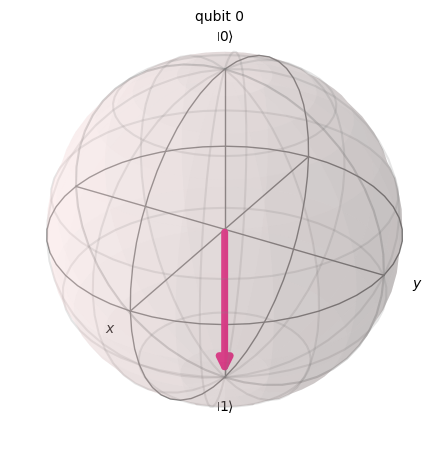

In [ ]:
# Define the quantum circuit with only one quantum qubit
my_qc = QuantumCircuit(1)


# TODO: Put your code here
# Apply a y or z gate to qubit 0
my_qc.y(0)
my_qc.z(0)


### YOUR CODE FINISHES HERE    ###


# See the statevector
out_vector = Statevector(my_qc)
print("\n")
print(out_vector)
print("\n")
# Draw a Bloch sphere
plot_bloch_multivector(out_vector)

### 2 Hadamard Gate and Superposition

Quantum computing holds great promise largely due to the principle of **quantum superposition**, which allows a qubit to exist in a combination of both basis states $|0\rangle$ and $|1\rangle$ simultaneously. This capability enables quantum algorithms to explore multiple computational paths in parallel, offering potential speedups over classical approaches.

 One of the fundamental tools for creating superposition is the **Hadamard gate**, which transforms a qubit from a definite state into an equal superposition of both basis states. The Hadamard gate is represented by the matrix:

\begin{align}
H = \frac{1}{\sqrt{2}}\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
\end{align}




When applied to the initial state $|0\rangle$, the **Hadamard gate** creates equal superpositions:

$$
H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}
$$



placing the qubit on the equator of the Bloch sphere along the X-axis. This transformation is essential in many quantum algorithms, including the famous **Deutsch-Jozsa**, **Grover's**, and **Shor's** algorithms, where superposition is a key enabler of quantum parallelism.

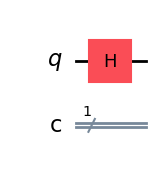

In [ ]:
# Create the single-qubit quantum circuit, with a classical bit to store the information
qc = QuantumCircuit(1,1)


# Apply an Hadamard gate to qubit 0
qc.h(0)

# Draw the circuit
qc.draw(output="mpl")


Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))



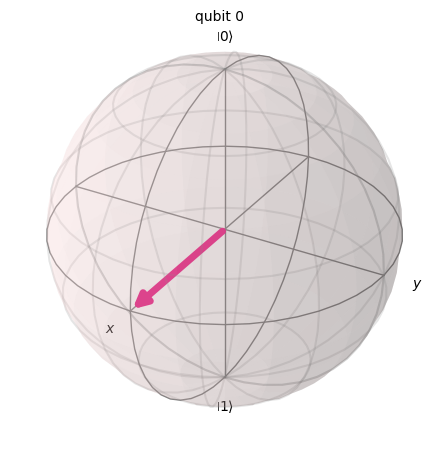

In [ ]:
# See the statevector
out_vector = Statevector(qc)
print(f"\n{out_vector}\n")


# Draw a Bloch sphere
plot_bloch_multivector(out_vector)

In [ ]:
# Print the plus state in Dirac notation
out_vector.draw('latex')

<IPython.core.display.Latex object>

In General: a quantum state of a single qubit is expressed as a **superposition** of the two basis states, denoted by $|0\rangle$ and $|1\rangle$. Mathematically, the general state of a qubit can be written as:

$$
|\psi\rangle = \alpha |0\rangle + \beta |1\rangle
$$

where $\alpha$ and $\beta$ are complex numbers, and $|\alpha|^2 + |\beta|^2 = 1$ to satisfy normalization.

<details>
<summary> <h3>Quantum Measurement Details: Observing the Qubit </h3> <b>(Click to Expand)</b> </summary>


**1. Act of Measurement:**
**Quantum Measurement** in the computational basis ($\{|0\rangle, |1\rangle\}$) forces the qubit to choose one **quantum state**. The **Quantum Superposition** is not directly observable.

**2. Probabilistic Outcomes:**
* Probability of measuring $|0\rangle$: $P(0) = |\alpha|^2 $
* Probability of measuring $|1\rangle$: $P(1) = |\beta|^2 $

**3. State Collapse:**
Post-measurement, the **quantum state** collapses:
* If '0' is measured $\rightarrow$ state becomes $|0\rangle$.
* If '1' is measured $\rightarrow$ state becomes $|1\rangle$.
    
This "collapse" effect destroys the **Quantum Superposition**.


</details>

Now that our quantum circuit is ready, we can execute it and collect measurement outcomes to verify whether the qubit indeed exhibits a 50% probability of being in each basis state. To obtain statistically meaningful results, we rely on the law of large numbers, which states that the average of results from a large number of trials tends to converge to the expected value. Therefore, we must run the experiment with a sufficiently large number of shots—repeated executions of the circuit—to accurately estimate the probability distribution of the qubit's final state.

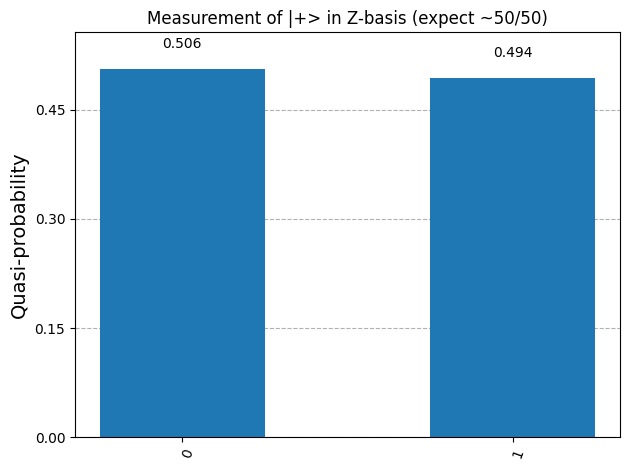

In [ ]:
# Measure the qubit
qc.measure(0, 0)

# Get the counts (measurement results)
counts = run_counts(qc, shots=2000)

counts = complete_counts(counts)

# Plot the histogram of the results
plot_histogram(probs_from_counts(counts), title= r"Measurement of |+> in Z-basis (expect ~50/50)")
# counts

### 🧩 Challenge 1 — Prepare |−⟩ and verify basis change (15-20mins)

1. Create a one‑qubit circuit that prepares $|{-}\rangle = \tfrac{1}{\sqrt{2}}(|0\rangle - |1\rangle)$.
2. **Measure in the Z basis** and observe the (roughly) 50/50 split.
3. **Measure in the X basis** by inserting an extra `H` *before* measurement. You should now see a distribution peaked at `1` (or `0`, depending on convention).

**Hint:** You can refer to the Block Sphere and try to figure out how you can get your desired states using some of the quantun gates you have seen so far. You can do it!

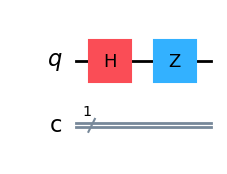

In [ ]:
# YOUR CODE HERE
qc_minus_z = QuantumCircuit(1,1)

# TODO: prepare |->, then measure in Z
# qc_minus_z.x(0)
# qc_minus_z.h(0)


qc_minus_z.h(0)
qc_minus_z.z(0)
# qc_minus_z.measure(0,0)
### YOUR CODE FINISHES HERE    ###

qc_minus_z.draw('mpl')


Statevector([ 0.70710678+0.j, -0.70710678+0.j],
            dims=(2,))



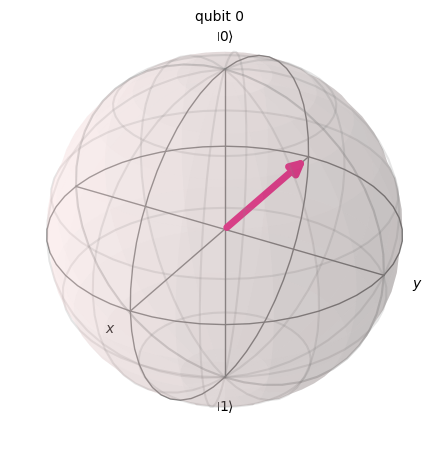

In [ ]:
# Optional -- visulaze your state on the Block Sphere
# See the statevector
qc = qc_minus_z
out_vector = Statevector(qc)
print(f"\n{out_vector}\n")

# Draw a Bloch sphere
plot_bloch_multivector(out_vector)

In [ ]:
# Print the minus state in Dirac notation
out_vector.draw('latex')

<IPython.core.display.Latex object>

Counts (Z): {'0': 1012, '1': 988} 



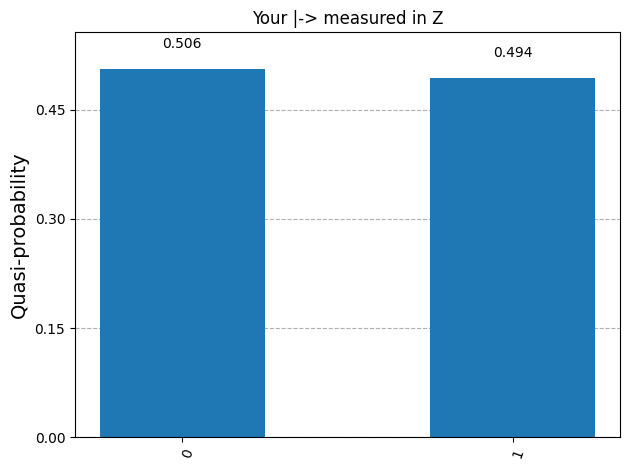

In [ ]:
# Measure the qubit
qc_minus_z.measure(0,0)

# Get the counts (measurement results)
# Z-basis should be ~50/50
counts_minus_z = run_counts(qc_minus_z, shots=2000)
print("Counts (Z):", counts_minus_z, "\n")

# Get the measurement probabilities
probs = probs_from_counts(complete_counts(counts_minus_z))
# Plot the histogram of the results
plot_histogram(data=probs, title="Your |-> measured in Z")

Now measure your |-> in the X basis by adding an H before measurement

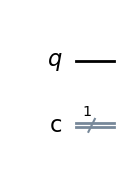

In [ ]:
# Now measure your |-> in the X basis by adding an H before measurement
# YOUR CODE HERE
qc_minus_x = QuantumCircuit(1,1)
# TODO: prepare |->, add H, then measure


qc_minus_x.draw('mpl')

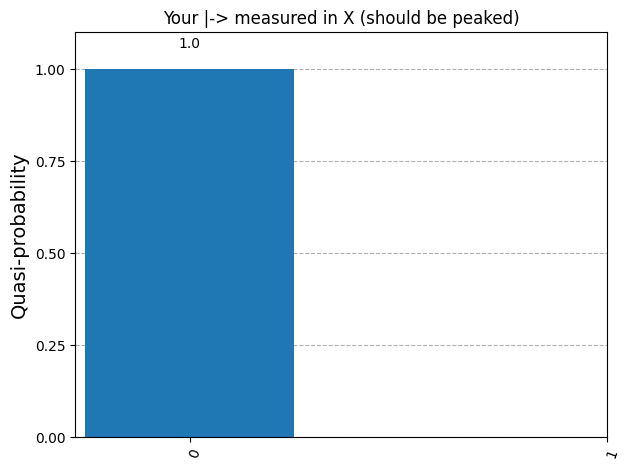

In [ ]:
# Measure the qubit
qc_minus_x.measure(0,0)

# Get the counts (measurement results)
counts_minus_x = run_counts(qc_minus_x, shots=2000)



# Get the measurement probabilities
probs = probs_from_counts(complete_counts(counts_minus_x))
plot_histogram(data=probs, title="Your |-> measured in X (should be peaked)")


### 3 Single-Qubit Rotation Gates: $\mathbf{R_x, R_y, R_z}$

**Intution.** These gates rotate a qubit's Bloch vector by an angle $\theta$ about the $X$, $Y$, or $Z$ axis.
All angles are in radians.
The X, Y and Z gates we have already seen are a special case of these rotation where $\theta = π$ up to a global phase.

### Definitions & matrices

For Pauli $X,Y,Z$ and rotation angle $\theta$:

$$
R_X(\theta)=e^{-i\theta X/2}=
\begin{bmatrix}
\cos\frac{\theta}{2} & -i\sin\frac{\theta}{2}\\
-i\sin\frac{\theta}{2} & \cos\frac{\theta}{2}
\end{bmatrix},\qquad
R_Y(\theta)=e^{-i\theta Y/2}=
\begin{bmatrix}
\cos\frac{\theta}{2} & -\sin\frac{\theta}{2}\\
\sin\frac{\theta}{2} & \cos\frac{\theta}{2}
\end{bmatrix},\qquad
R_Z(\theta)=e^{-i\theta Z/2}=
\begin{bmatrix}
e^{-i\theta/2} & 0\\
0 & e^{+i\theta/2}
\end{bmatrix}.
$$

### Key effects from $|0\rangle$

$$
\begin{align}
R_Y(\theta)|0\rangle
&= \cos\frac{\theta}{2}\,|0\rangle + \sin\frac{\theta}{2}\,|1\rangle
\quad\Rightarrow\quad \Pr(1)=\sin^2\!\left(\frac{\theta}{2}\right),\\[6pt]
R_X(\theta)|0\rangle
&= \cos\frac{\theta}{2}\,|0\rangle - i\sin\frac{\theta}{2}\,|1\rangle
\quad\Rightarrow\quad \Pr(1)=\sin^2\!\left(\frac{\theta}{2}\right)\ \text{(same as $R_Y$, phase differs)},\\[6pt]
R_Z(\theta)|0\rangle &= e^{-i\theta/2}\,|0\rangle,\qquad
R_Z(\theta)|1\rangle = e^{+i\theta/2}\,|1\rangle\\
\end{align}
$$

$$
\begin{align}
\Rightarrow\ \text{Z-basis probabilities are unchanged, but X/Y-basis statistics can change (phase effect).}
\end{align}
$$

**Special cases**

$$
R_x(\pi) = -i\,X,\quad R_y(\pi) = -i\,Y,\quad R_z(\pi) = -i\,Z.
$$

So,

$$
X \equiv R_x(\pi),\quad Y \equiv R_y(\pi),\quad Z \equiv R_z(\pi)
$$

*up to a global phase* \( $-i$ \) (physically unobservable).





### Task: (5mins)

Goal: Start from
∣0⟩, apply
Ry(θ), visualize the state on the Bloch sphere, and verify the coordinates you predict.

Statevector([0.8660254+0.j, 0.5      +0.j],
            dims=(2,))


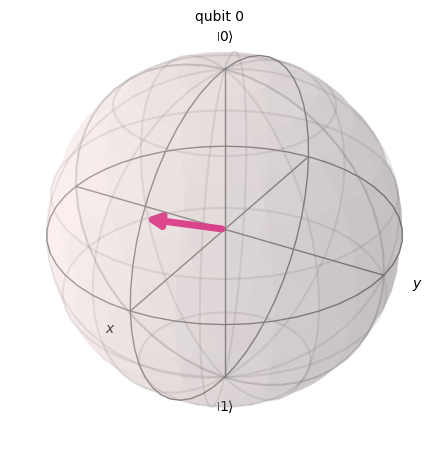

In [ ]:

# === Enter your angle (degrees) ===
theta_deg = 60                      # <- change me
theta = np.deg2rad(theta_deg)

# === Prepare state and apply Ry(θ) ===
qc = QuantumCircuit(1,1)
qc.ry(theta, 0)


# See the statevector
out_vector = Statevector(qc)
print(out_vector)

# === 3) Visualise on Bloch sphere (from the statevector) ===
# Draw a Bloch sphere
plot_bloch_multivector(out_vector)


### 🧩 Challenge 2 — Target a probability (10-15mins)

Build a 1‑qubit circuit that outputs `1` about **85%** of the time in the Z basis.  
**Hint:** A single `ry(θ)` rotation on $|0\rangle$ yields $\Pr(1)=\sin^2(θ/2)$.

You can calculate the value of $\theta$ theoretically from the above formula

Statevector([0.38729833+0.j, 0.92195445+0.j],
            dims=(2,))


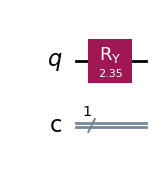

In [ ]:
# YOUR CODE HERE
qc_85 = QuantumCircuit(1,1)
# TODO: choose theta, apply ry(theta) to |0>, then measure

# Choose the correct θ
theta = 2*np.arcsin(np.sqrt(0.85))   # choose θ so that P(1)=0.85

qc_85.ry(theta, 0)



# See the statevector
out_vector = Statevector(qc_85)
print(out_vector)


# draw the circuit
qc_85.draw('mpl')

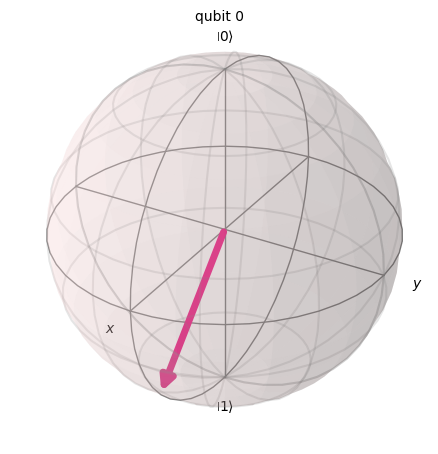

In [ ]:
# === Visualise on Bloch sphere (from the statevector) ===
# Draw a Bloch sphere
plot_bloch_multivector(out_vector)

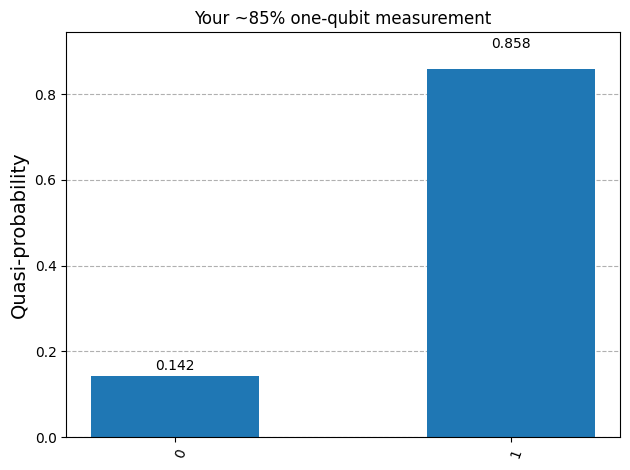

In [ ]:
# Measure the qubit
qc_85.measure(0,0)
# Get the measurement counts
c85 = run_counts(qc_85, shots=4000)
# Get the measurement probabilities
probs = probs_from_counts(c85)
plot_histogram(probs, title="Your ~85% one-qubit measurement")


---

# Recreating Famous Experiments at Home

## Double-Slit Experiment - Superposition and Interference
<a id="double-slit-experiment"></a>

To finish up strong this exciting journey(lab.), we will dive into **Quantum Superposition**, **Quantum Interference**, and **Quantum Measurement** through the famous **Double-Slit Experiment**. **Quantum Superposition** means a **quantum particle** - for example, an **electron** or a **photon** — *can exist in multiple states at once*, like *being in two places or having two energies at the same time*. It is like *flipping a coin with the result of heads and tails at the same time*... *until you look*! **Quantum Interference** describes what happens when these *quantum possibilities*, behaving like *waves*, *overlap*. *If they are in phase*, they reinforce each other* (**constructive interference**), and *if out of
phase, they can weaken or cancel each other out* (**destructive interference**).
<br>
<br>
<br>
One of the most famous experiments demonstrating these concepts is the **Double-Slit Experiment**, first done by *Thomas Young* in 1801 [\[1\]](https://royalsocietypublishing.org/doi/10.1098/rstl.1804.0001) and later repeated with *individual particles* like *electrons* [\[2\]](https://www.nature.com/articles/119890a0). *When no one watches which slit the particle goes through, the result is a beautiful interference pattern, like waves overlapping*. *But the moment you* **measure** *which slit it goes through, the pattern disappears*. *It is as if the particle knows it is being watched*!
<br>
<br>

This strange idea was taken to the next level by *Erwin Schrödinger* in 1935 with the famous thought experiment known as **Schrödinger's Cat** [\[4\]](https://link.springer.com/article/10.1007/BF01491891), where *a cat can be both alive and dead until someone opens the box to check*. **Quantum Measurement** *in* **Quantum Mechanics** *does not just observe reality, it shapes it*.
<br>
<br>

Ready to experience quantum weirdness yourself? With **Qiskit**, you can do the **Double-Slit Experiment** - *with and without* **Quantum Measurement** - *and see for yourself the beautiful patterns of* **Quantum Superposition** *and* **Quantum Interference**, as well as the effects that **Quantum Measurement** has on **quantum systems**. It is a fun and eye-opening way to explore the mysteries of the **quantum world**!

***

***

<p style="text-align:center;">
    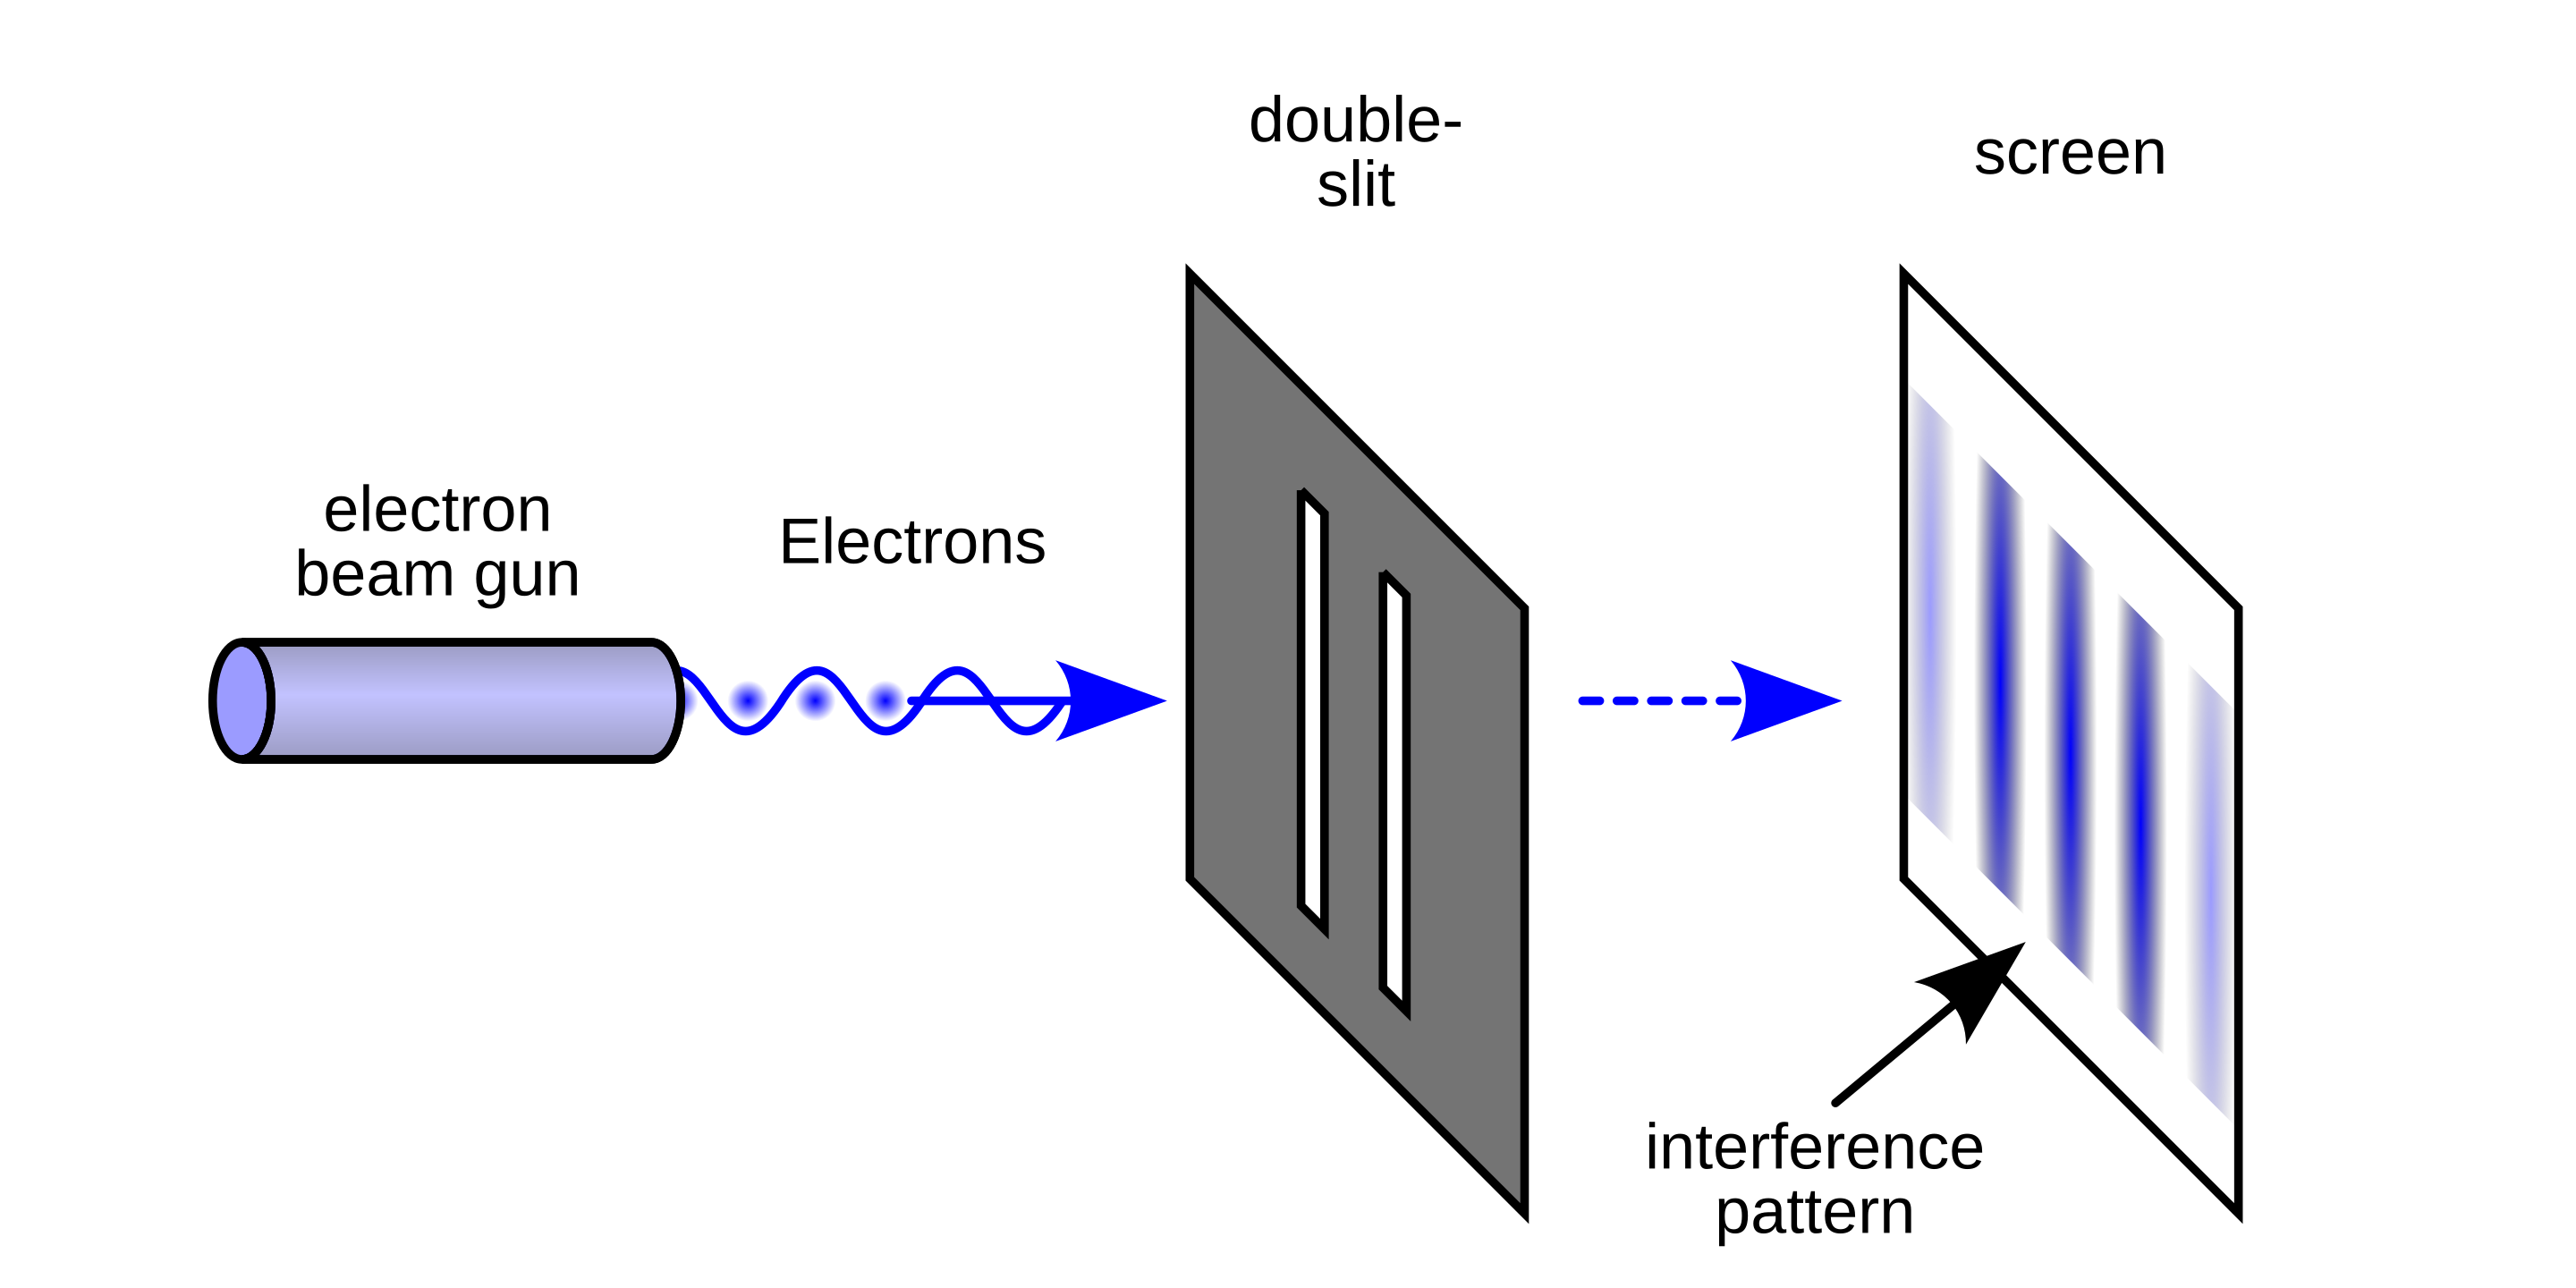
</p>
<p style="text-align:center;">
    image from wikipedia
</p>



In his paper **"Experiments and Calculations Relative to Physical Optics"** (1803), *Thomas Young* explains about his experiments in this quotation:
> I made a small hole in a window-shutter, and covered it with a piece of thick paper, which I perforated with a fine needle. For greater convenience of observation, I placed a small looking glass without the window-shutter, in such a positioned as to reflect the sun's light, in a direction nearly horizontal, upon the opposite wall, and to cause the cone of diverging light to pass over a table, on which were several little screens of card-paper. [\[1\]](https://royalsocietypublishing.org/doi/10.1098/rstl.1804.0001)

<br>
<br>

With this experiment, he could observe *beautiful fringe patterns by light* and explained *this comes from the differences in the lengths of the paths of two rays*. *George Thomson* later reproduced a similar experiment using *electrons* (**Electron Diffraction Experiment**), and showed that even *particles* like *electrons* *exhibit wave-like behavior*, as demonstrated in his 1927 paper. [\[2\]](https://www.nature.com/articles/119890a0) Later in 1965, *Richard Feynman* explained the **Double-Slit Experiment** in his **"Lectures on Physics, Vol. 3, Chapter 1"** [\[3\]](https://www.feynmanlectures.caltech.edu/III_toc.html), and explained *this comes from the* **Quantum Superposition** *and* **Quantum Interference** *concepts of* **Quantum Mechanics**.
<br>
<br>

Now, we can reproduce this fascinating **quantum phenomenon** using **Qiskits**, without complex physical equipment. Let's see how **Quantum Superposition** and **Quantum Interference** are implemented in **Quantum Circuits**.
<br>
<br>

The first step is mapping the physical **Double-Slit Experiment** to a **Quantum Circuit**, which is your first exercise.

<div class="alert alert-block alert-success">
<b>Exercise 1: Build a Quantum Circuit for the Double-Slit Experiment</b>

-   Exercise 1.1: Make a Double-Slit.

**Your Goal:** Create a **Quantum Circuit** that models a *particle* (qubit) passing through two slits, achieving a **Quantum Superposition** of being in the $|0\rangle$ (lower slit) and $|1\rangle$ (upper slit) states.

* Let's define the upper slit as the $|1\rangle$ state of a qubit and the lower slit as the $|0\rangle$ state;
* Implement a **Quantum Circuit** where a qubit, initially in $|0\rangle$, passes through the slits in a **Quantum Superposition** of $|0\rangle$ and $|1\rangle$ using the [Hadamard gate](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.circuit.library.HGate). Draw your **Quantum Circuit**.

**Hint**: It can be beneficial for clarity to assign specific names to `QuantumRegister` (e.g., `name='q'`) and `ClassicalRegister` (e.g., `name='c_screen'`) when interpreting measurement data.

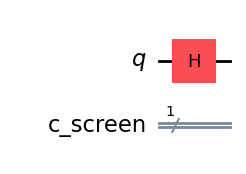

In [ ]:
# Import the Quantum Circuit, Quantum Register,
# and Classical Register modules from the Qiskit library
from qiskit import QuantumCircuit,\
                   QuantumRegister, ClassicalRegister


# Create a Quantum Register,
# with one quantum bit
qr = QuantumRegister(1, name = "q")

# Create a Classical Register for the screen,
# on which the Quantum Interference will be recorded,
# with one classical bit
cr = ClassicalRegister(1, name = "c_screen")

# Create a new Quantum Circuit
# to recreate the Double-Slit Experiment,
# with the Quantum Register and
# Classical Register defined before
double_slit = QuantumCircuit(qr, cr)


### WRITE YOUR CODE BELOW HERE ###

#
double_slit.h(0)

### YOUR CODE FINISHES HERE    ###


# Return a drawing of the Quantum Circuit
# for the Double-Slit Experiment
# using the MatPlotLib library ("mpl")
double_slit.draw("mpl")

<div class="alert alert-block alert-success">
<b>Exercise 1: Build a Quantum Circuit for the Double-Slit Experiment</b>

-   Exercise 1.2: Make a screen

**Your Goal:** Extend the previous **Quantum Circuit** to model the screen where **Quantum Interference** occurs. Specifically, implement the center of the screen where no phase difference is introduced, and then measure the qubit.

* Now, implement the screen where the two **superposed quantum states** create a **quantum interference pattern** by adding a gate;
* First, let's implement the center of the screen, where the two beams combine with no phase difference (resulting in the $|0\rangle$ state);
* Then, measure the qubit from `qr` and store the result in `c_screen`.

**Hint**: You can use the Hadamard gate again.
</div>

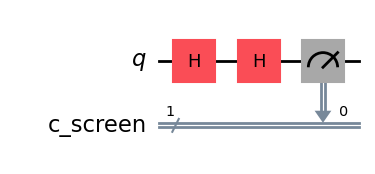

In [ ]:
### WRITE YOUR CODE BELOW HERE ###

# Add a H (Hadamard) gate to qubit 0
double_slit.h(0)

# Add measurement operations to all qubits
double_slit.measure(qr, cr)

### YOUR CODE FINISHES HERE    ###


# Return a drawing of the Quantum Circuit
# for the Double-Slit Experiment
# using the MatPlotLib library ("mpl")
double_slit.draw("mpl")

Let's check the execution result. Assuming the screen detects the qubit in the $|0\rangle$ state, the following code runs the **Quantum Circuit** on an ideal simulator. A probability of $1.0$ means $100$%.

<div class="alert alert-block alert-info">
<b>Note on Retrieving Measurement Results with SamplerV2</b>

When using *SamplerV2* in **Qiskit**, how you retrieve measurement counts depends on how you have set up your **classical registers** and **Quantum Measurements**:

* 1.  Named **Classical Register** in **QuantumCircuit**:
    If you define your circuit with a named classical register, e.g., *cr = ClassicalRegister(1, name='my_results')* and *qc = QuantumCircuit(qr, cr)*, and then measure to it *qc.measure(qr[0], cr[0])*, you access the counts using that name:

    
    ```python
    # result = job.result()
    # counts = result[0].data.my_results.get_counts()
    ```
    
    In our double-slit circuit, we used *cr = ClassicalRegister(1, name='c_screen')*, so we will use *result[0].data.c_screen.get_counts()*.
<br><br>
* 2.  measure_all():
    If you use *qc.measure_all()*, Qiskit automatically adds classical bits and names the output data field `meas`:

    
    ```python
    # qc.measure_all()
    # ...
    # counts = result[0].data.meas.get_counts()
    ```
<br><br>
* 3.  Implicit Classical Bits (No Named Register in *QuantumCircuit*):
    If you create a circuit like *qc = QuantumCircuit(1, 1)* (1 qubit, 1 classical bit) or *qc = QuantumCircuit(QuantumRegister(1), ClassicalRegister(1))* without naming the classical register in its constructor, and then use *qc.measure(0, 0)*, the *SamplerV2* might store results under a default name (often *c*, or based on the classical bit indices like *c0*).
    For *qc = QuantumCircuit(1,1)* and *qc.measure(0,0)*, the output might be accessed as follows:

    ```python
     # counts = result[0].data.c0.get_counts() # If single bit named c0, the indice can vary. You can see the actual indices when you plot your circuit.
    ```
</div>

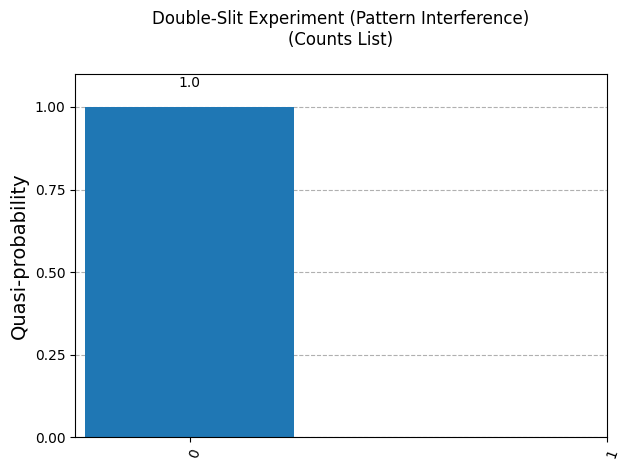

In [ ]:
# Set up the Backend from the Qiskit Aer Simulator
backend = AerSimulator()

# Create the Pass Manager for the transpilation of
# the Quantum Circuit for the Backend defined before
# and with some optimization settings
pass_manager = generate_preset_pass_manager\
               (backend = backend,
                optimization_level = 3)

# Run and retrieve the Quantum Circuit transpiled
qc_isa = pass_manager.run(double_slit)

# Set up the Sampler with the Backend defined before
sampler = Sampler(mode = backend)

# Submit the transpiled Quantum Circuit
# to the Sampler and execute it,
# retrieving the list of discrete counts of
# the measurements on the results from the Sampler
counts = sampler.run([qc_isa], shots = 1000)\
                .result()[0].data.c_screen.get_counts()

counts = complete_counts(counts)
# Plot the probability distribution of
# the obtained list of discrete counts of
# the measurements on the results from the Sampler
plot_histogram(probs_from_counts(counts),
                  title = "Double-Slit Experiment (Pattern Interference)" + \
                          "\n(Counts List)\n")

<div class="alert alert-block alert-success">
<br>
<b>Exercise 1: Build a Quantum Circuit for the Double-Slit Experiment</b>

-   Exercise 1.3: Make a Difference

**Your Goal:** Modify the **Double-Slit** **Quantum Circuit** to introduce a **phase difference** between the two paths (slits) and observe its effect on the measurement outcome at the screen.

* Now, let's implement another part of the screen;
* The path difference between the two beams is implemented as a phase difference between $|0\rangle$ and $|1\rangle$;
* Apply a phase of $\pi/2$ only to the $|1\rangle$ state of the superposed quantum state and observe the measurement results.
    
**Hint:** Use a gate that applies a phase to the $|1\rangle$ state. The [**P gate**](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.circuit.library.PhaseGate) and the [**S gate**](https://quantum.cloud.ibm.com/docs//api/qiskit/qiskit.circuit.library.SGate) are representative examples.
</div>

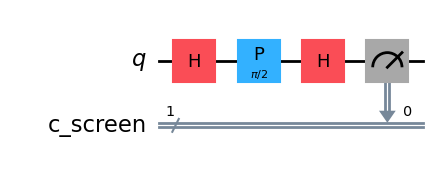

In [ ]:
# Create a Quantum Register,
# with one quantum bit
qr = QuantumRegister(1, name = "q")

# Create a Classical Register for the screen,
# on which the Quantum Interference will be recorded,
# with one classical bit
cr = ClassicalRegister(1, name = "c_screen")

# Create a new Quantum Circuit
# to recreate the Double-Slit Experiment,
# with the Quantum Register and
# Classical Register defined before
double_slit_with_difference = QuantumCircuit(qr, cr)


# Add a H (Hadamard) gate to qubit 0
double_slit_with_difference.h(0)

### WRITE YOUR CODE BELOW HERE ###

# Add a P (Phase) gate with pi/2 radians to qubit 0
double_slit_with_difference.p(np.pi/2, 0)

### YOUR CODE FINISHES HERE    ###


# Add a H (Hadamard) gate to qubit 0
double_slit_with_difference.h(0)

# Add measurement operations to all qubits
double_slit_with_difference.measure(qr, cr)

# Return a drawing of the Quantum Circuit
# using the MatPlotLib library ("mpl")
double_slit_with_difference.draw("mpl")

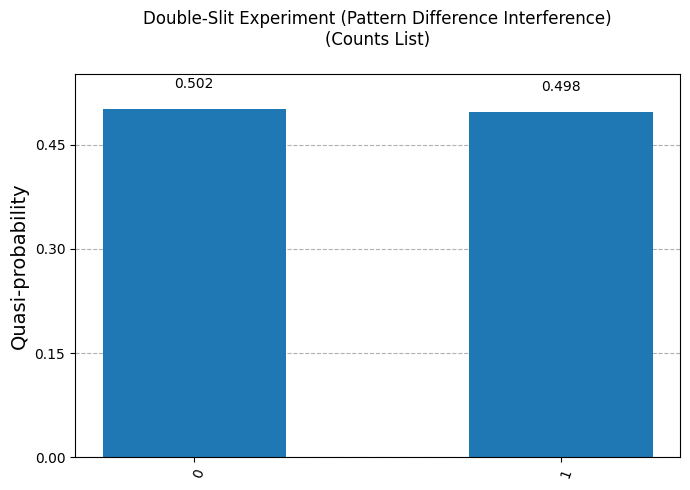

In [ ]:
# Run and retrieve the Quantum Circuit transpiled
qc_isa = pass_manager.run(double_slit_with_difference)

# Set up the Sampler with the Backend defined before
sampler = Sampler(mode = backend)

# Submit the transpiled Quantum Circuit
# to the Sampler and execute it,
# retrieving the list of discrete counts of
# the measurements on the results from the Sampler
counts = sampler.run([qc_isa], shots = 1000)\
                .result()[0].data.c_screen.get_counts()

# Plot the probability distribution of
# the obtained list of discrete counts of
# the measurements on the results from the Sampler
plot_distribution(counts,
                  title = "Double-Slit Experiment (Pattern Difference Interference)" + \
                          "\n(Counts List)\n")

As you can see, the probability of measuring $|0\rangle$ decreased to approximately 0.5 (50%), signifying reduced brightness at this point on the screen.

***

Before we go further, let's do a simple mathematics demonstration of this process in regards to **Quantum Superposition**, **Quantum Interference**, and the probability of measuring a **quantum state**. You can skip this part if you are already familiar with this concept.

***

<details>
<summary> <h3>Superposition, Interference and the Probability of Measurement </h3> <b>(Click to Expand)</b> </summary>

In our <b>Quantum Circuit</b> implementation of the <b>Double-Slit Experiment</b>, we used a sequence of <b>Hadamard (H)</b> gates and a <b>Phase (P)</b> gate. Let's break down the mathematical representation of the <b>quantum state</b> at each step and analyze the <b>Quantum Superposition</b>, <b>Quantum Interference</b>, and <b>measurement probability</b>.

**1. Initialization:**

We start with a single qubit initialized in the $|0\rangle$ state, representing the *electron* starting at a source before the slits:

$$ |\psi_0\rangle = |0\rangle = \begin{pmatrix} 1 \\ 0 \end{pmatrix} $$

Here, we will assume $ |\psi_1^{'}\rangle$ is another **quantum state** that can pass the upper slit - this will be:

$$ |\psi_1^{'}\rangle = |1\rangle = \begin{pmatrix} 0 \\ 1 \end{pmatrix} $$

**2. Superposition (First Hadamard Gate):**

The first **Hadamard (H)** gate is applied to the qubit. This operation creates a **Quantum Superposition** of the $|0\rangle$ and $|1\rangle$ states, representing the *electron* passing through both slits simultaneously:

$$ H = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix} $$

Applying **H** to $|\psi_0\rangle$:

$$ |\psi_1\rangle = H |\psi_0\rangle = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix} \begin{pmatrix} 1 \\ 0 \end{pmatrix} = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 \\ 1 \end{pmatrix} = \frac{1}{\sqrt{2}} (|0\rangle + |1\rangle) $$

This state $|\psi_1\rangle$ shows the qubit is in an equal **Quantum Superposition** of the $|0\rangle$ state (representing one slit) and the $|1\rangle$ state (representing the other slit).

**3. Phase Shift (P Gate):**

The **Phase (P)** gate introduces a **relative phase** $\phi$ between the $|0\rangle$ and $|1\rangle$ components of the **Quantum Superposition**. This **phase difference** corresponds to the path difference experienced by the *electron* waves passing through the two slits in the physical experiment. The **P** gate is defined as:

$$ P(\phi) = \begin{pmatrix} 1 & 0 \\ 0 & e^{i\phi} \end{pmatrix} $$

Applying P($\phi$) to $|\psi_1\rangle$:

$$ |\psi_2\rangle = P(\phi) |\psi_1\rangle = \begin{pmatrix} 1 & 0 \\ 0 & e^{i\phi} \end{pmatrix} \frac{1}{\sqrt{2}} \begin{pmatrix} 1 \\ 1 \end{pmatrix} = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 \\ e^{i\phi} \end{pmatrix} = \frac{1}{\sqrt{2}} (|0\rangle + e^{i\phi}|1\rangle) $$

The state $|\psi_2\rangle$ now contains the **relative phase** information, which is crucial for **Quantum Interference**.

**4. Interference (Second Hadamard Gate):**

The second **Hadamard (H)** gate is applied to bring the **quantum superposed states** back together, allowing them to interfere:

$$ |\psi_3\rangle = H |\psi_2\rangle = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix} \frac{1}{\sqrt{2}} \begin{pmatrix} 1 \\ e^{i\phi} \end{pmatrix} = \frac{1}{2} \begin{pmatrix} 1 + e^{i\phi} \\ 1 - e^{i\phi} \end{pmatrix} $$

Expanding $e^{i\phi} = \cos(\phi) + i\sin(\phi)$:

$$ |\psi_3\rangle = \frac{1}{2} \begin{pmatrix} 1 + \cos(\phi) + i\sin(\phi) \\ 1 - (\cos(\phi) + i\sin(\phi)) \end{pmatrix} = \frac{1}{2} \begin{pmatrix} (1 + \cos(\phi)) + i\sin(\phi) \\ (1 - \cos(\phi)) - i\sin(\phi) \end{pmatrix} $$

This final **quantum state** before measurement embodies the interference effect, where the probabilities of measuring $|0\rangle$ or $|1\rangle$ depend on the **phase difference** $\phi$.

**5. Probability of Measurement:**

The probability of measuring the qubit in the $|0\rangle$ state (corresponding to one part of the screen) is given by the squared magnitude of the amplitude of $|0\rangle$ in $|\psi_3\rangle$:

$$ P(|0\rangle) = \left| \frac{1}{2} (1 + e^{i\phi}) \right|^2 = \left| \frac{1}{2} (1 + \cos(\phi) + i\sin(\phi)) \right|^2 $$

$$ P(|0\rangle) = \frac{1}{4} [(1 + \cos(\phi))^2 + (\sin(\phi))^2] = \frac{1}{4} [1 + 2\cos(\phi) + \cos^2(\phi) + \sin^2(\phi)] $$

Using the identity $\cos^2(\phi) + \sin^2(\phi) = 1$:

$$ P(|0\rangle) = \frac{1}{4} [1 + 2\cos(\phi) + 1] = \frac{1}{4} [2 + 2\cos(\phi)] = \frac{1}{2} (1 + \cos(\phi)) $$

In case of $\phi = \pi/2$, $P(|0\rangle) = \frac{1}{2} (1 + \cos(\pi/2)) = 0.5$, as we checked already.

</details>

Let's conclude Exercise 1 by generating the fringe pattern using a range of $\phi$.

<div class="alert alert-block alert-success">
<b>Exercise 1: Build a Quantum Circuit for the Double-Slit Experiment</b>

-   Exercise 1.4: Beautiful Fringes

**Your Goal:** Create a **Parameterized Quantum Circuit (PQC)** where the **phase difference** $\phi$ can be varied, allowing you to simulate and visualize the **complete interference fringe pattern**.

* **Qiskit** allows [using `Parameters` in **Quantum Circuits**](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.circuit.Parameter);
* We will use this with the `Sampler` to observe interference fringes;
* Define a **Parameterized Quantum Circuit (PQC)** for the **Double-Slit Experiment** with a variable parameter $\phi$;
* A common structure is **H** gate, then **P**$(\phi)$ gate, then another **H** gate, before measurement;
* Measure `q` and save to `c_screen`.
</div>

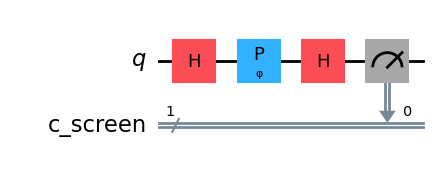

In [ ]:
# Define the phi parameter
φ = Parameter("φ")


# Create a Quantum Register,
# with one quantum bit
qr = QuantumRegister(1, name = "q")

# Create a Classical Register for the screen,
# on which the Quantum Interference will be recorded,
# with one classical bit
cr = ClassicalRegister(1, name = "c_screen")

# Create a new Quantum Circuit
# to recreate the Double-Slit Experiment,
# with the Quantum Register and
# Classical Register defined before
double_slit_fringe = QuantumCircuit(qr, cr)


### WRITE YOUR CODE BELOW HERE ###

# Add a H (Hadamard) gate to qubit 0
double_slit_fringe.h(0)


# Add a parameterized P (Phase) gate to qubit 0
double_slit_fringe.p(φ, 0)

# Add a H (Hadamard) gate to qubit 0
double_slit_fringe.h(0)

# Add measurement operations to all qubits
double_slit_fringe.measure(qr, cr)

### YOUR CODE FINISHES HERE    ###


# Return a drawing of the Quantum Circuit
# using the MatPlotLib library ("mpl")
double_slit_fringe.draw("mpl")

***

Excellent! Now, let's use this **Parameterized Quantum Circuit (PQC)** to plot the **fringe pattern** using **MatPlotLib**'s **Heat Map**. The code below generates 100 **phase values**, runs the **Quantum Circuits** (1000 shots each) via `Sampler`, stores the probability of measuring $|0\rangle$, and plots the **Heat Map**.

***

<div class="alert alert-block alert-warning">
<b>Resource Limit:</b>

* When running the code below on an actual backend, increasing the number of parameters or shots consumes more **QPU** time than might be expected;
* The current configuration (100 **Parameterized Quantum Circuit (PQC)** + 1000 shots) uses less than 1 minute of **QPU** time, so please try to maintain these settings if possible.

</div>

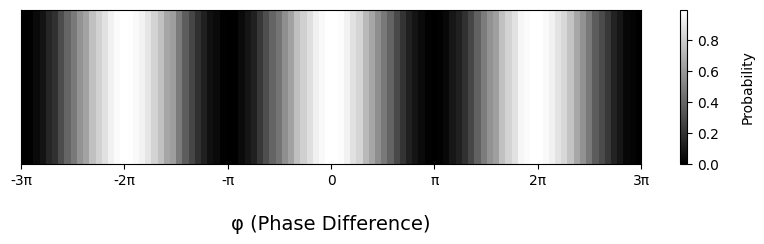

In [ ]:
# Define a list for variable phi values
# from a linear space of 100 points within [-3pi,3pi]
φ_lst = np.linspace(-3 * np.pi, 3 * np.pi, 100)

# Run and retrieve the Quantum Circuit transpiled
qc_isa = pass_manager.run(double_slit_fringe)


# Define a list of hits on the screen
# for the list of variable phi values
φ_hit = []

# Submit the transpiled Quantum Circuit
# to the Sampler and execute it,
# retrieving the measurements
# on the results from the Sampler
dist = sampler.run([(qc_isa, φ_lst)], shots = 1000)\
              .result()[0].data.c_screen


# For every index of variable phi values
for i in range(len(φ_lst)):

    # Retrieve the discrete counts
    # from the current variable phi value
    result = dist[i].get_counts()

    # If current variable phi value
    # results on a hit on the screen
    if "0" in result:

        # Append a probability of 1.0 (100%) to
        # the respective variable phi value
        φ_hit.append(result["0"] / 1000)

    # If current variable phi value
    # does not result on a hit on the screen
    else:

        # Append a probability of 0.0 (0%) to
        # the respective variable phi value
        φ_hit.append(0)


# Define a two-dimensional heat map
# for the resulting hits on the screen
# regarding the variable phi values
φ_hit_2d = np.array(φ_hit).reshape(1, -1)


# Create a figure for plotting
plt.figure(figsize = (10, 2))

# Define the plot for the two-dimensional
# heat map for the resulting hits on the screen
# regarding the variable phi values
plt.imshow(φ_hit_2d, cmap = "gray", aspect = "auto",
           extent = [-3 * np.pi, 3 * np.pi, 0, 0.1])

# Define the label for the x-axis of the heat map plot
plt.xlabel("\nφ (Phase Difference)", fontsize = 14)

# Define the label for the color of bars
plt.colorbar(label = "\nProbability")

# Define the ticks for the x-axis
plt.xticks(ticks = [-3 * np.pi, -2 * np.pi, -np.pi, 0, np.pi, 2 * np.pi, 3 * np.pi],
           labels = ["-3π", "-2π", "-π", "0", "π", "2π", "3π"])

# Clear the ticks for the y-axis
plt.yticks([])


# Show the heat map plot for the hits on the screen,
# representing the fringe pattern of the Double-Slit Experiment
plt.show()

Fantastic! You've reproduced the **Double-Slit Experiment**'s fringes using qubits.

***

### Double-Slit Experiment Summary

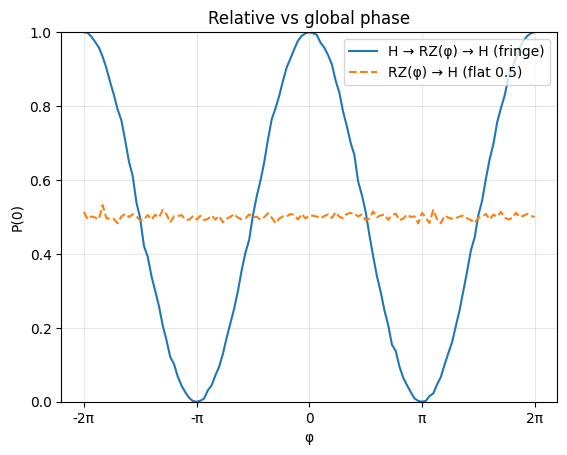

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit_aer import Aer

backend = Aer.get_backend("aer_simulator")
shots = 4000
phis = np.linspace(-2*np.pi, 2*np.pi, 121)

# A) H → RZ(φ) → H (relative phase visible)
phi = Parameter("φ")
qa = QuantumCircuit(1,1)
qa.h(0)
qa.rz(phi,0)
qa.h(0)
qa.measure(0,0)

# B) RZ(φ) → H (φ is global on |0>, so invisible)
phi2 = Parameter("φ")
qb = QuantumCircuit(1,1)
qb.rz(phi2,0)
qb.h(0)
qb.measure(0,0)

p0A, p0B = [], []
for v in phis:
    resA = backend.run(transpile(qa.assign_parameters({phi: float(v)}), backend), shots=shots).result().get_counts()
    resB = backend.run(transpile(qb.assign_parameters({phi2: float(v)}), backend), shots=shots).result().get_counts()
    p0A.append(resA.get('0',0)/shots)
    p0B.append(resB.get('0',0)/shots)

plt.plot(phis, p0A, label='H → RZ(φ) → H (fringe)')
plt.plot(phis, p0B, '--', label='RZ(φ) → H (flat 0.5)')
plt.ylim(0,1); plt.grid(alpha=.3); plt.legend()
plt.xlabel("φ"); plt.ylabel("P(0)"); plt.title("Relative vs global phase")
plt.xticks([-2*np.pi,-np.pi,0,np.pi,2*np.pi], ["-2π","-π","0","π","2π"])
plt.show()


## References

1. Young, Thomas (1804) I. The Bakerian Lecture. Experiments and Calculations Relative to Physical Optics. Phil. Trans. R. Soc. 941–16.
2. Thomson, George and Reid, Alexander (1927). Diffraction of Cathode Rays by a Thin Film.  Nature 119(3007), 890.
3. Feynman, Richard (1965). Lectures on Physics. Vol. 3. Quantum Mechanics.
4. Schrödinger, Erwin (1935). Die Gegenwärtige Situation in der Quantenmechanik. Naturwissenschaften 23, 807–812.

---
## Acknowledgements

Portions of this notebook are adapted from **IBM’s Qiskit Global Summer School 2025 — Lab 1**  
(Created by: Sophy Shin, James Weaver; Advised by: Marcel Pfaffhauser, Jessie Yu, Junye Huang, Borja Peropadre;  
Reviewed by: Meltem Tolunay, Abby Cross; Version 1.1.1) and from the community adaptation by **Rúben André Barreiro** (adapted from IBM Quantum).  
Original: https://github.com/rubenandrebarreiro/ibm-qiskit-global-summer-school-2025/blob/main/labs/jupyter-notebooks/lab-1-recreating-famous-experiments-at-home.ipynb

*Licensed and shared under the terms of the original repositories’ LICENSE files.*


---

Congratulations! You finished this Qiskit Fall Fest 2025 lab! 🎉🎉🎉

Made with ❤ by **Otmane Ainelkitane** (UC OpenSI) & **Pranay Khosla** (ANU).
